In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

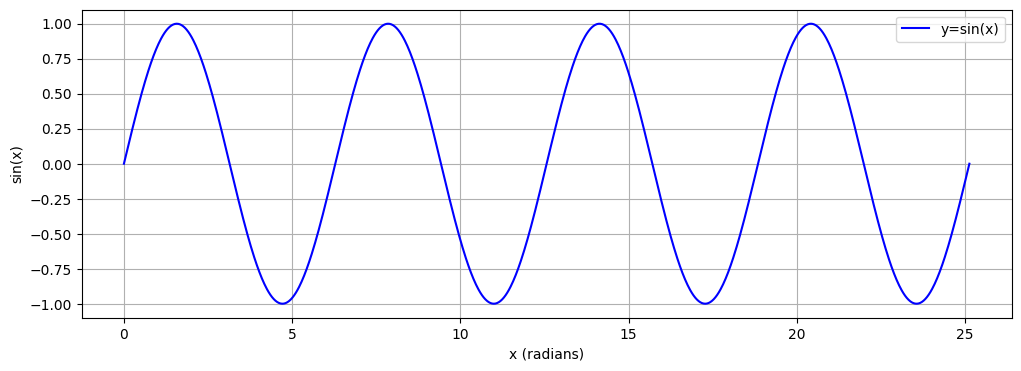

In [ ]:
# Sample 1000 evenly spaced points from 0 to 8pi
x = torch.unsqueeze(torch.linspace(0, 8*np.pi, 1000), dim=1).to(device)  # input
y = torch.sin(x) # output

# Plot data
plt.figure(figsize=(12, 4))
plt.plot(x.cpu().numpy(), y.cpu().numpy(), label='y=sin(x)', color="blue")
plt.legend(loc=1)
plt.xlabel("x (radians)")
plt.ylabel("sin(x)")
plt.grid(True)
plt.show()

In [ ]:
# Define neural network
class SinCurveApproximatorNetwork(nn.Module):
    def __init__(self):
        super(SinCurveApproximatorNetwork, self).__init__()
        self.fc1 = nn.Linear(1, 20)
        self.fc2 = nn.Linear(20, 100)
        self.fc3 = nn.Linear(100, 20)
        self.fc4 = nn.Linear(20, 10)
        self.fc5 = nn.Linear(10, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = torch.relu(self.fc3(x))
        x = torch.tanh(self.fc4(x))
        x = self.fc5(x)
        return x

In [ ]:
model = SinCurveApproximatorNetwork()
model.to(device)

SinCurveApproximatorNetwork(
  (fc1): Linear(in_features=1, out_features=20, bias=True)
  (fc2): Linear(in_features=20, out_features=100, bias=True)
  (fc3): Linear(in_features=100, out_features=20, bias=True)
  (fc4): Linear(in_features=20, out_features=10, bias=True)
  (fc5): Linear(in_features=10, out_features=1, bias=True)
)

In [ ]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}")

Total parameters: 4,381


In [ ]:
# Define loss function and optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

In [ ]:
# Training the model
num_epochs = 50000
for epoch in range(num_epochs):
    # Forward pass
    outputs = model(x)
    loss = criterion(outputs, y)

    # Backward pass and optimization
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    if (epoch+1) % 500 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

Epoch [500/50000], Loss: 0.4449
Epoch [1000/50000], Loss: 0.3720
Epoch [1500/50000], Loss: 0.3424
Epoch [2000/50000], Loss: 0.2905
Epoch [2500/50000], Loss: 0.2288
Epoch [3000/50000], Loss: 0.1918
Epoch [3500/50000], Loss: 0.0930
Epoch [4000/50000], Loss: 0.0419
Epoch [4500/50000], Loss: 0.0167
Epoch [5000/50000], Loss: 0.0106
Epoch [5500/50000], Loss: 0.0083
Epoch [6000/50000], Loss: 0.0067
Epoch [6500/50000], Loss: 0.0054
Epoch [7000/50000], Loss: 0.0042
Epoch [7500/50000], Loss: 0.0034
Epoch [8000/50000], Loss: 0.0027
Epoch [8500/50000], Loss: 0.0021
Epoch [9000/50000], Loss: 0.0017
Epoch [9500/50000], Loss: 0.0014
Epoch [10000/50000], Loss: 0.0012
Epoch [10500/50000], Loss: 0.0010
Epoch [11000/50000], Loss: 0.0008
Epoch [11500/50000], Loss: 0.0007
Epoch [12000/50000], Loss: 0.0006
Epoch [12500/50000], Loss: 0.0007
Epoch [13000/50000], Loss: 0.0005
Epoch [13500/50000], Loss: 0.0005
Epoch [14000/50000], Loss: 0.0004
Epoch [14500/50000], Loss: 0.0004
Epoch [15000/50000], Loss: 0.0004


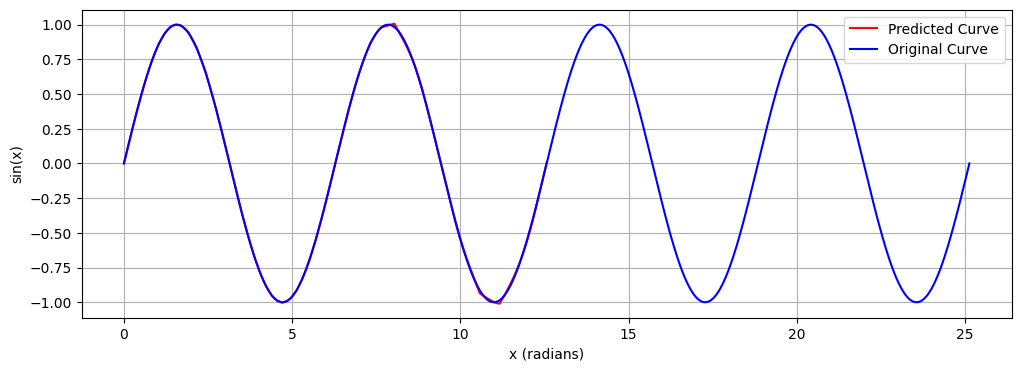

In [ ]:
# Inference within trained domain
x_test = torch.unsqueeze(torch.linspace(0, 4*np.pi, 3000), dim=1).to(device)  # additional test data
y_pred = model(x_test).detach()

plt.figure(figsize=(12, 4))
plt.plot(x_test.cpu().numpy(), y_pred.cpu().numpy(), label='Predicted Curve', color="red")
plt.plot(x.cpu().numpy(), y.cpu().numpy(), label='Original Curve', color="blue")
plt.legend(loc=1)
plt.xlabel("x (radians)")
plt.ylabel("sin(x)")
plt.grid(True)
plt.show()

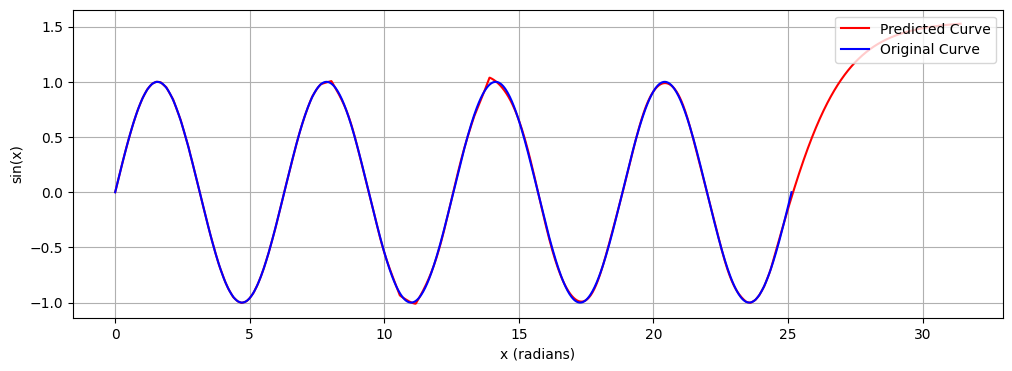

In [ ]:
# Inference outside trained domain
x_test = torch.unsqueeze(torch.linspace(0, 10*np.pi, 2000), dim=1).to(device)  # additional test data
y_pred = model(x_test).detach()

plt.figure(figsize=(12, 4))
plt.plot(x_test.cpu().numpy(), y_pred.cpu().numpy(), label='Predicted Curve', color="red")
plt.plot(x.cpu().numpy(), y.cpu().numpy(), label='Original Curve', color="blue")
plt.legend(loc=1)
plt.xlabel("x (radians)")
plt.ylabel("sin(x)")
plt.grid(True)
plt.show()